In [18]:
from dfft.utils.files import get_path
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import re
import json

In [ ]:
def extract_time(d):
    m = re.match(r"(\d{8}_\d{6})", os.path.basename(d))
    return m.group(1) if m else ""

def get_lastest_exp(base_dir):
    exp_dirs = [os.path.join(base_dir, d) for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]
    exp_dirs = sorted(exp_dirs, key=extract_time, reverse=True)
    return exp_dirs[-1]

In [20]:
names = ['moment-small', 'moment-base', 'moment-large']
configs=["-finetuned", "-lora"]
losses = ["", "-decision"]
models = [ name + c + l for name in names for c in configs for l in losses]
models.append('moment-small-zeroshot')
models.append('moment-base-zeroshot')
models.append('moment-large-zeroshot')

In [21]:
#Create a table of regret, mse by model and data split
all = []
for model in models:
    base_dir = get_path(f"results\\experiments\\{model}\\NEMA")
    exp_dir = get_lastest_exp(base_dir)
    df = pd.read_parquet(exp_dir + "/results.parquet")
    #Compute regret
    result = df.groupby('split')[['true_profit', 'real_profit']].sum()
    result['model'] = model
    result['regret'] = (result['true_profit'] - result['real_profit']) / result['true_profit']
    result['regret'] = (result['regret'] * 100).round(1)
    all.append(result.reset_index())

regret = pd.concat(all, axis= 0)
#Reshape data
regret = regret[['model', 'split', 'regret']]
regret = regret.pivot(index='model', columns='split', values='regret')
regret = regret.sort_values('model')
print(regret)

FileNotFoundError: [Errno 2] No such file or directory: 'H:\\My Drive\\Study\\Sem 2\\10707 Advanced Deep Learning\\Project\\decision-focused-fine-tuning\\results\\experiments\\moment-small-finetuned\\NEMA\\20260423_173539_v2/results.parquet'

In [ ]:
all=[]
for model in models:
    base_dir = get_path(f"results\\experiments\\{model}\\NEMA")
    exp_dir = get_lastest_exp(base_dir)
    with open(exp_dir + "/results.json", 'r') as f:
            data = json.load(f)
    df = pd.DataFrame([model], columns=["model"])
    df["test_mse"] = data['test_results']['mse']
    df["val_mse"] = data['final_val_results']['mse']
    df["train_mse"] = data['final_train_results']['mse']
    all.append(df)

mse  = pd.concat(all, axis= 0)
print(mse)

                             model     test_mse      val_mse    train_mse
0           moment-small-finetuned  1425.428833  1228.364014   957.241272
0  moment-small-finetuned-decision  2459.853760  1679.445801  2157.851074
0                moment-small-lora  1426.075806  1227.158936   982.956726
0       moment-small-lora-decision  2521.183105  1719.716431  2240.185791
0            moment-base-finetuned  1449.115356  1229.195068   923.970520
0   moment-base-finetuned-decision  2356.553955  1628.137573  2105.221680
0                 moment-base-lora  1451.318970  1229.216675   910.887207
0        moment-base-lora-decision  2809.929688  1872.331787  2566.955322
0           moment-large-finetuned  1409.101318  1242.135376   933.712585
0  moment-large-finetuned-decision  2250.712891  1617.128174  2015.442627
0                moment-large-lora  1406.375366  1240.238037   953.742920
0       moment-large-lora-decision  2253.629883  1615.110596  2008.418701
0            moment-small-zeroshot  21

In [ ]:
metrics = pd.merge(mse, regret, on='model', how='inner')
print(metrics.sort_values('model'))

                              model     test_mse      val_mse    train_mse  \
4             moment-base-finetuned  1449.115356  1229.195068   923.970520   
5    moment-base-finetuned-decision  2356.553955  1628.137573  2105.221680   
6                  moment-base-lora  1451.318970  1229.216675   910.887207   
7         moment-base-lora-decision  2809.929688  1872.331787  2566.955322   
13             moment-base-zeroshot  2153.526855  1523.163330  1962.787231   
8            moment-large-finetuned  1409.101318  1242.135376   933.712585   
9   moment-large-finetuned-decision  2250.712891  1617.128174  2015.442627   
10                moment-large-lora  1406.375366  1240.238037   953.742920   
11       moment-large-lora-decision  2253.629883  1615.110596  2008.418701   
14            moment-large-zeroshot  2087.747070  1483.763428  1918.667480   
0            moment-small-finetuned  1425.428833  1228.364014   957.241272   
1   moment-small-finetuned-decision  2459.853760  1679.445801  2

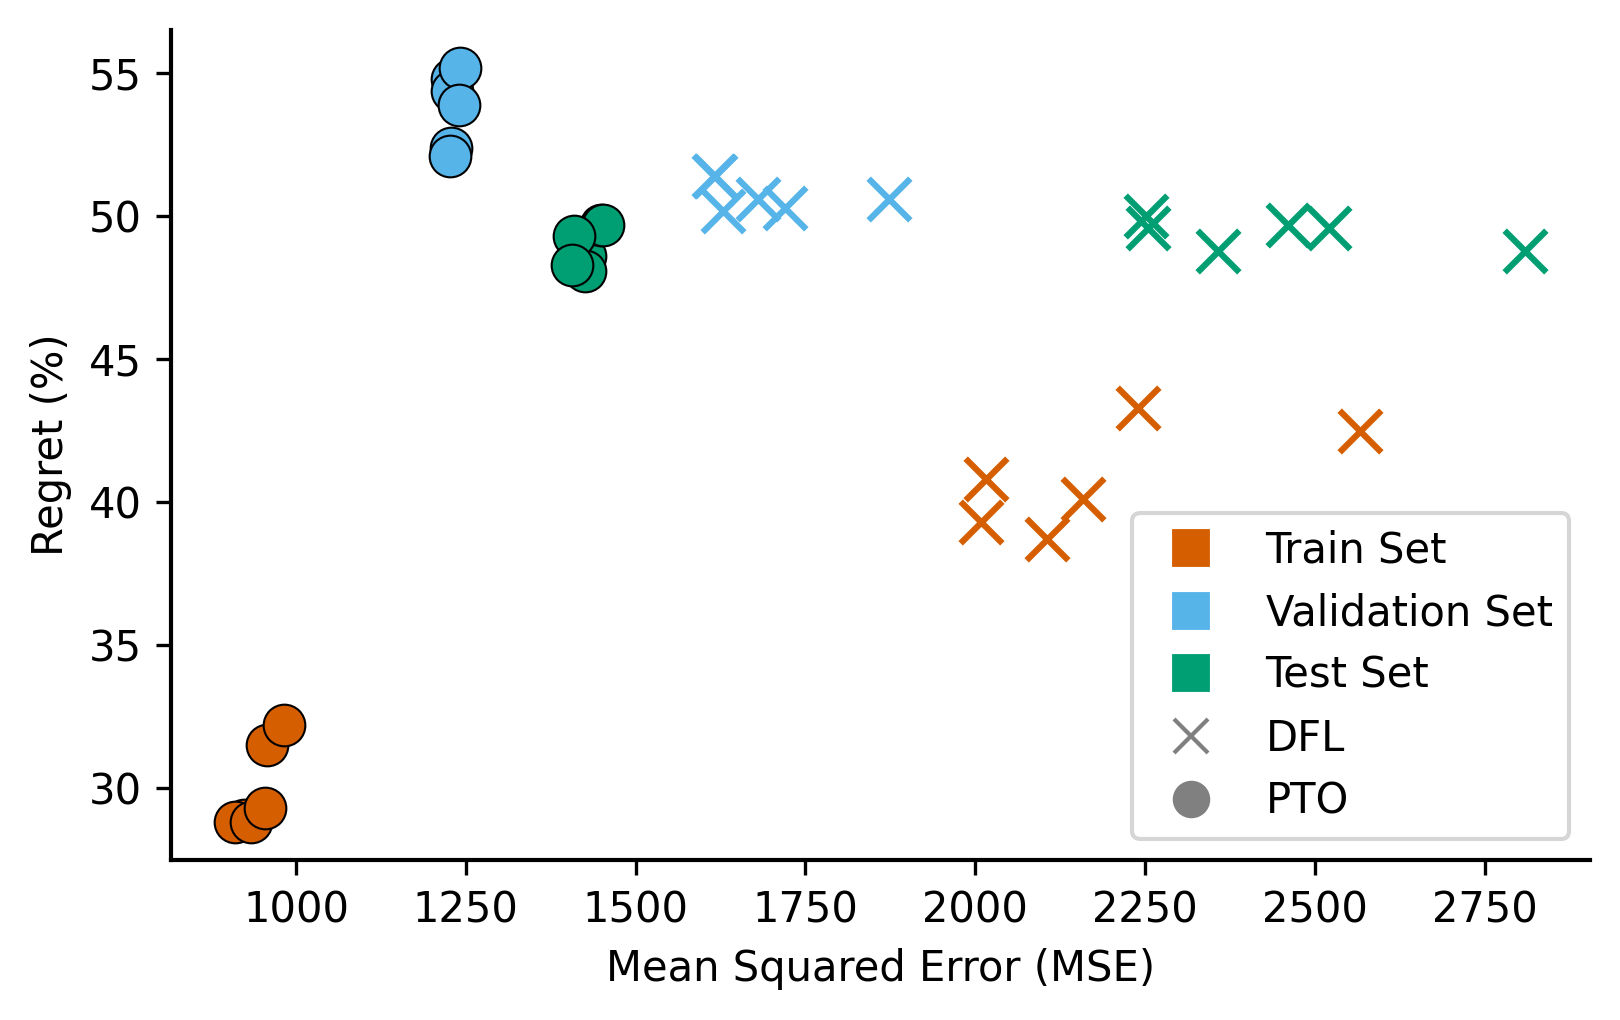

In [ ]:
#Create a scatter plot of Regret vs. MSE
dfl = metrics.loc[metrics['model'].str.contains('decision')]
pto = metrics.loc[(~metrics['model'].str.contains('decision')) & (~metrics['model'].str.contains('zeroshot'))]

plt.style.use('default')
fig, ax = plt.subplots(figsize=(5.5, 3.5), dpi=300)

ax.scatter(dfl["train_mse"], dfl["train"], color='#D55E00', marker='x', s=100, label='Train (dfl)')
ax.scatter(dfl["val_mse"], dfl["val"], color='#56B4E9', marker='x', s=100, label='Val (dfl)')
ax.scatter(dfl["test_mse"], dfl["test"], color='#009E73', marker='x', s=100, label='Test (dfl)')
ax.scatter(pto["train_mse"], pto["train"], color='#D55E00', marker='o', s=100, edgecolors='k', linewidth=0.5, label='Train (pto)')
ax.scatter(pto["val_mse"], pto["val"], color='#56B4E9', marker='o', s=100, edgecolors='k', linewidth=0.5, label='Val (pto)')
ax.scatter(pto["test_mse"], pto["test"], color='#009E73', marker='o', s=100, edgecolors='k', linewidth=0.5, label='Test (pto)')

ax.set_xlabel('Mean Squared Error (MSE)', fontsize=10)
ax.set_ylabel('Regret (%)', fontsize=10)

legend_elements = [
    # Color indicators
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='Train Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='Validation Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#009E73', markersize=10, label='Test Set'),
    # Marker indicators
    Line2D([0], [0], color='gray', marker='x', linestyle='None', markersize=8, label='DFL'),
    Line2D([0], [0], color='gray', marker='o', linestyle='None', markersize=8, label='PTO')
]


ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(handles=legend_elements, loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
plt.savefig("plots/regret_vs_mse.pdf", format='pdf', bbox_inches='tight') 
plt.show()

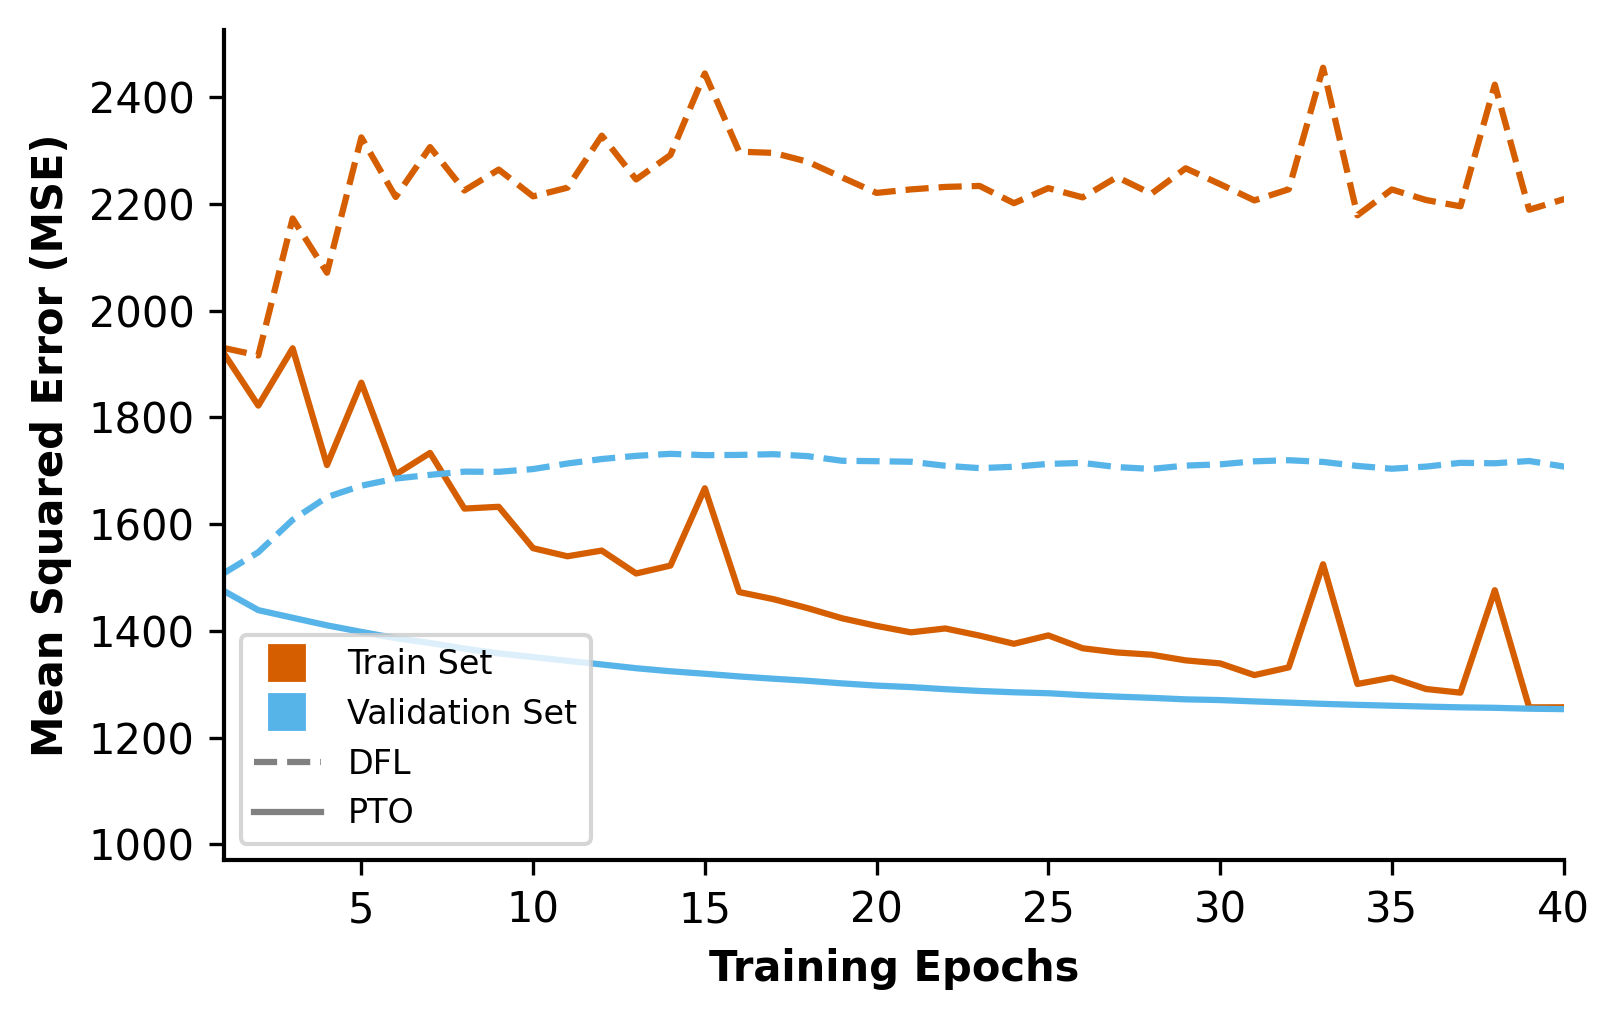

In [ ]:
#Plot trajectories for moment-small-lora


#Read training data

#moment-small-lora
base_dir = get_path(f"results\\experiments\\moment-small-lora\\NEMA")
exp_dir = get_lastest_exp(base_dir)
with open(exp_dir + "/results.json", 'r') as f:
        pto = json.load(f)

#moment-small-lora-decision
base_dir = get_path(f"results\\experiments\\moment-small-lora-decision\\NEMA")
exp_dir = get_lastest_exp(base_dir)
with open(exp_dir + "/results.json", 'r') as f:
        dfl = json.load(f)
dfl["training_history"]["train"]["mse"]

#Generate plot
plt.style.use('default')
fig, ax = plt.subplots(figsize=(5.5, 3.5), dpi=300)

#Training
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["train"]["mse"],
        linestyle= "--",
        color = '#D55E00'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["train"]["mse"],
        linestyle= "-",
        color = '#D55E00'
)

#Validation
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["val"]["mse"],
        linestyle= "--",
        color = '#56B4E9'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["val"]["mse"],
        linestyle= "-",
        color = '#56B4E9'
)


ax.set_xlabel('Training Epochs', fontweight='bold', fontsize=10)
ax.set_ylabel('Mean Squared Error (MSE)', fontweight='bold', fontsize=10)

ax.set_xlim(xmin=1, xmax=40)

legend_elements = [
    # Color indicators
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='Train Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='Validation Set'),
    # Marker indicators
    Line2D([0], [0], color='gray', linestyle='--', label='DFL'),
    Line2D([0], [0], color='gray', linestyle='-', label='PTO')
]

ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
ax.legend(handles=legend_elements, loc='best', frameon=True, fontsize=8)

plt.tight_layout()
plt.savefig("plots/mse_traj.pdf", format='pdf', bbox_inches='tight') 
plt.show()

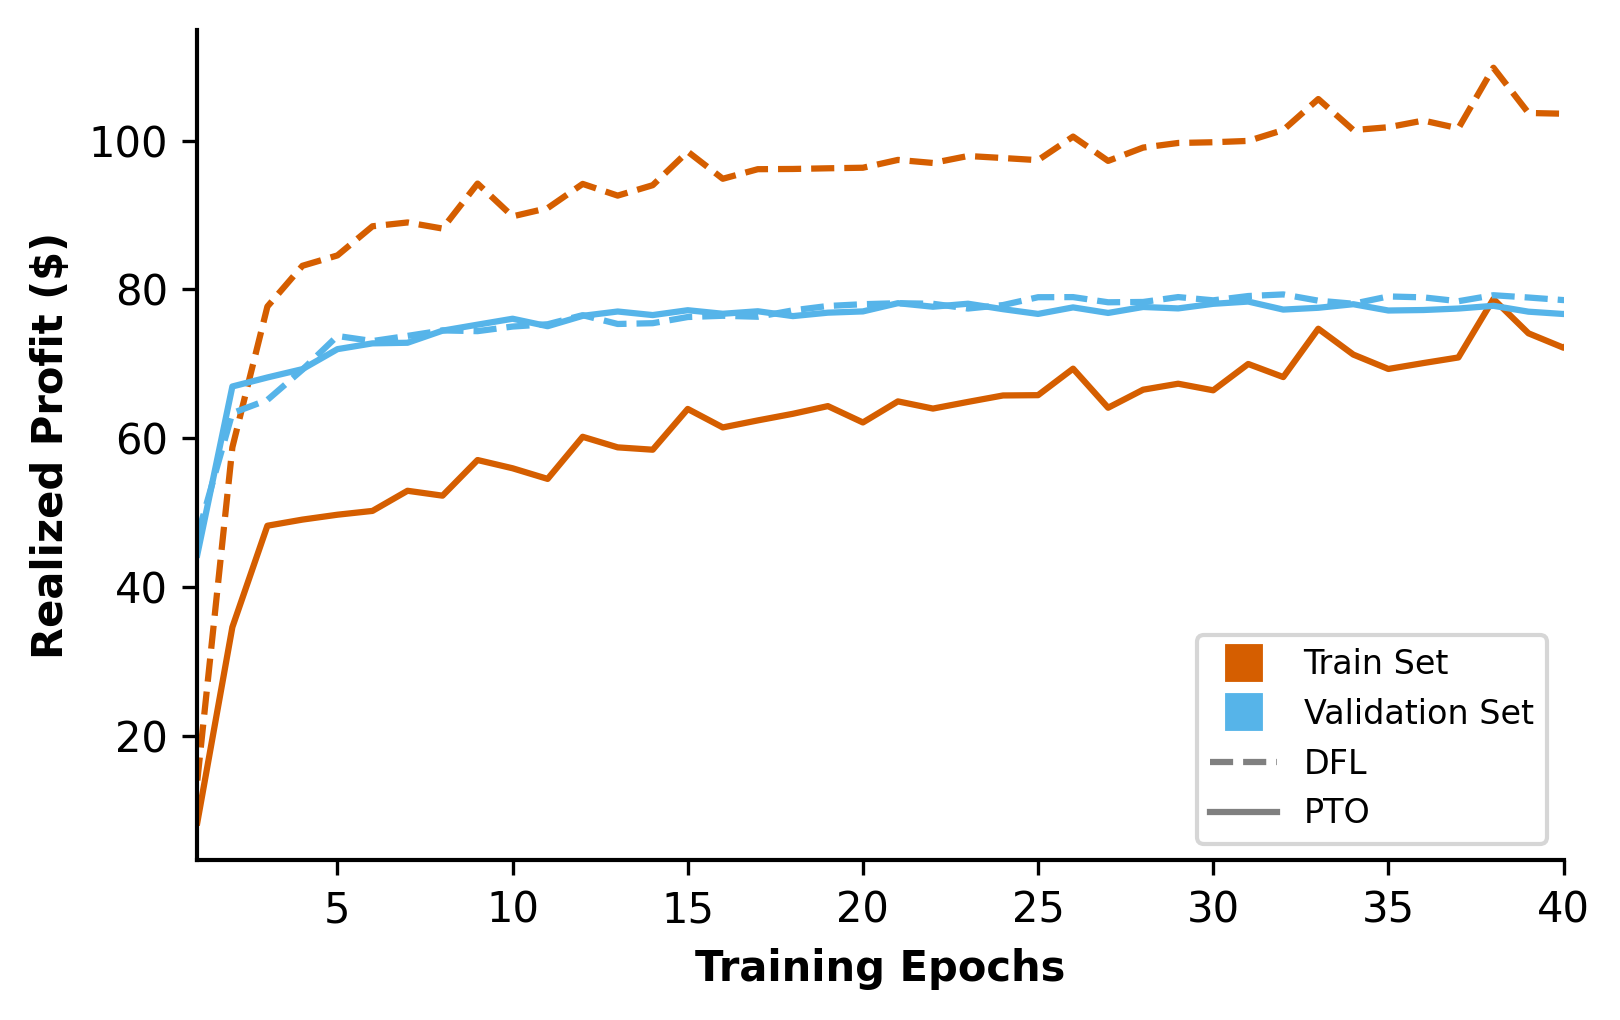

In [ ]:
#Generate plot
plt.style.use('default')
fig, ax = plt.subplots(figsize=(5.5, 3.5), dpi=300)

#Training
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["train"]["profit"],
        linestyle= "--",
        color = '#D55E00'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["train"]["profit"],
        linestyle= "-",
        color = '#D55E00'
)

#Validation
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["val"]["profit"],
        linestyle= "--",
        color = '#56B4E9'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["val"]["profit"],
        linestyle= "-",
        color = '#56B4E9'
)


ax.set_xlabel('Training Epochs', fontweight='bold', fontsize=10)
ax.set_ylabel('Realized Profit ($)', fontweight='bold', fontsize=10)

ax.set_xlim(xmin=1, xmax=40)

legend_elements = [
    # Color indicators
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='Train Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='Validation Set'),
    # Marker indicators
    Line2D([0], [0], color='gray', linestyle='--', label='DFL'),
    Line2D([0], [0], color='gray', linestyle='-', label='PTO')
]

ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
ax.legend(handles=legend_elements, loc='best', frameon=True, fontsize=8)

plt.tight_layout()
plt.savefig("plots/profit_traj.pdf", format='pdf', bbox_inches='tight') 
plt.show()

# NonTSFM

In [ ]:
def build_model_names():
    families = ["linear", "mlp", "lstm", "gru", "tcn"]
    variants = ["small", "base", "large"]
    loss_variants = ["", "-decision"]

    model_names = []
    for family in families:
        for variant in variants:
            for losser in loss_variants:
                model_names.append(f"{family}-{variant}{losser}")
    return model_names

def extract_learning_rate(exp_dir_name):
    m = re.search(r"_lr_([0-9]*\.?[0-9]+(?:e-?[0-9]+)?)", exp_dir_name, re.IGNORECASE)
    if not m:
        return None
    return float(m.group(1))

def get_latest_experiments_by_lr(base_dir):
    if not os.path.isdir(base_dir):
        return []

    latest_by_lr = {}
    for d in os.listdir(base_dir):
        exp_dir = os.path.join(base_dir, d)
        if not os.path.isdir(exp_dir):
            continue

        lr = extract_learning_rate(d)
        if lr is None:
            continue

        ts = extract_time(d)
        if lr not in latest_by_lr or ts > latest_by_lr[lr][0]:
            latest_by_lr[lr] = (ts, exp_dir)

    return [(lr, latest_by_lr[lr][1]) for lr in sorted(latest_by_lr.keys())]

models = build_model_names()

In [ ]:
# Create a table of regret by model, learning rate, and data split
all_regret = []
for model in models:
    base_dir = get_path(f"nontsfm\\{model}\\NEMA")
    for learning_rate, exp_dir in get_latest_experiments_by_lr(base_dir):
        df = pd.read_parquet(exp_dir + "/results.parquet")

        result = df.groupby('split')[['true_profit', 'real_profit']].sum()
        result['regret'] = (result['true_profit'] - result['real_profit']) / result['true_profit']
        result['regret'] = (result['regret'] * 100).round(1)

        row = {
            'model': model,
            'learning_rate': learning_rate
        }
        for split in ['train', 'val', 'test']:
            row[split] = result.loc[split, 'regret'] if split in result.index else np.nan
        all_regret.append(row)

regret = pd.DataFrame(all_regret)
regret = regret.sort_values(['model', 'learning_rate']).reset_index(drop=True)
print(regret)

                 model  learning_rate  train   val  test
0    gru-base-decision         0.0001   52.9  57.6  54.0
1    gru-base-decision         0.0010   72.9  71.9  73.6
2    gru-base-decision         0.0100   52.9  54.7  52.4
3            gru-large         0.0001   81.4  79.4  81.5
4            gru-large         0.0010   64.0  61.8  67.7
..                 ...            ...    ...   ...   ...
79           tcn-small         0.0010   53.9  56.0  52.2
80           tcn-small         0.0100   51.7  55.0  52.4
81  tcn-small-decision         0.0001   78.0  76.4  79.0
82  tcn-small-decision         0.0010   66.6  67.9  68.1
83  tcn-small-decision         0.0100   56.1  59.7  56.5

[84 rows x 5 columns]


In [ ]:
all_mse = []
for model in models:
    base_dir = get_path(f"nontsfm\\{model}\\NEMA")
    for learning_rate, exp_dir in get_latest_experiments_by_lr(base_dir):
        with open(exp_dir + "/results.json", 'r') as f:
            data = json.load(f)

        row = {
            'model': model,
            'learning_rate': learning_rate,
            'test_mse': data['test_results']['mse'],
            'val_mse': data['final_val_results']['mse'],
            'train_mse': data['final_train_results']['mse']
        }
        all_mse.append(row)

mse = pd.DataFrame(all_mse)
mse = mse.sort_values(['model', 'learning_rate']).reset_index(drop=True)
print(mse)

                 model  learning_rate      test_mse      val_mse    train_mse
0    gru-base-decision         0.0001   7703.962402  3247.327393  5602.909180
1    gru-base-decision         0.0010   7670.522461  3227.353027  5573.914062
2    gru-base-decision         0.0100   7648.048340  3214.285400  5555.891113
3            gru-large         0.0001   6926.035645  2799.083740  4960.521484
4            gru-large         0.0010   3385.952148  1425.521118  2313.284180
..                 ...            ...           ...          ...          ...
79           tcn-small         0.0010   1289.263916  1166.446289  1057.732544
80           tcn-small         0.0100   1283.133423  1160.054810  1025.333374
81  tcn-small-decision         0.0001   8048.729004  3390.809082  5862.539551
82  tcn-small-decision         0.0010   7316.778320  3146.291016  5342.592773
83  tcn-small-decision         0.0100  11399.556641  5133.783203  8412.175781

[84 rows x 5 columns]


In [ ]:
metrics = pd.merge(mse, regret, on=['model', 'learning_rate'], how='inner')
metrics = metrics.sort_values(['model', 'learning_rate']).reset_index(drop=True)
print(metrics)

                 model  learning_rate      test_mse      val_mse    train_mse  \
0    gru-base-decision         0.0001   7703.962402  3247.327393  5602.909180   
1    gru-base-decision         0.0010   7670.522461  3227.353027  5573.914062   
2    gru-base-decision         0.0100   7648.048340  3214.285400  5555.891113   
3            gru-large         0.0001   6926.035645  2799.083740  4960.521484   
4            gru-large         0.0010   3385.952148  1425.521118  2313.284180   
..                 ...            ...           ...          ...          ...   
79           tcn-small         0.0010   1289.263916  1166.446289  1057.732544   
80           tcn-small         0.0100   1283.133423  1160.054810  1025.333374   
81  tcn-small-decision         0.0001   8048.729004  3390.809082  5862.539551   
82  tcn-small-decision         0.0010   7316.778320  3146.291016  5342.592773   
83  tcn-small-decision         0.0100  11399.556641  5133.783203  8412.175781   

    train   val  test  
0  

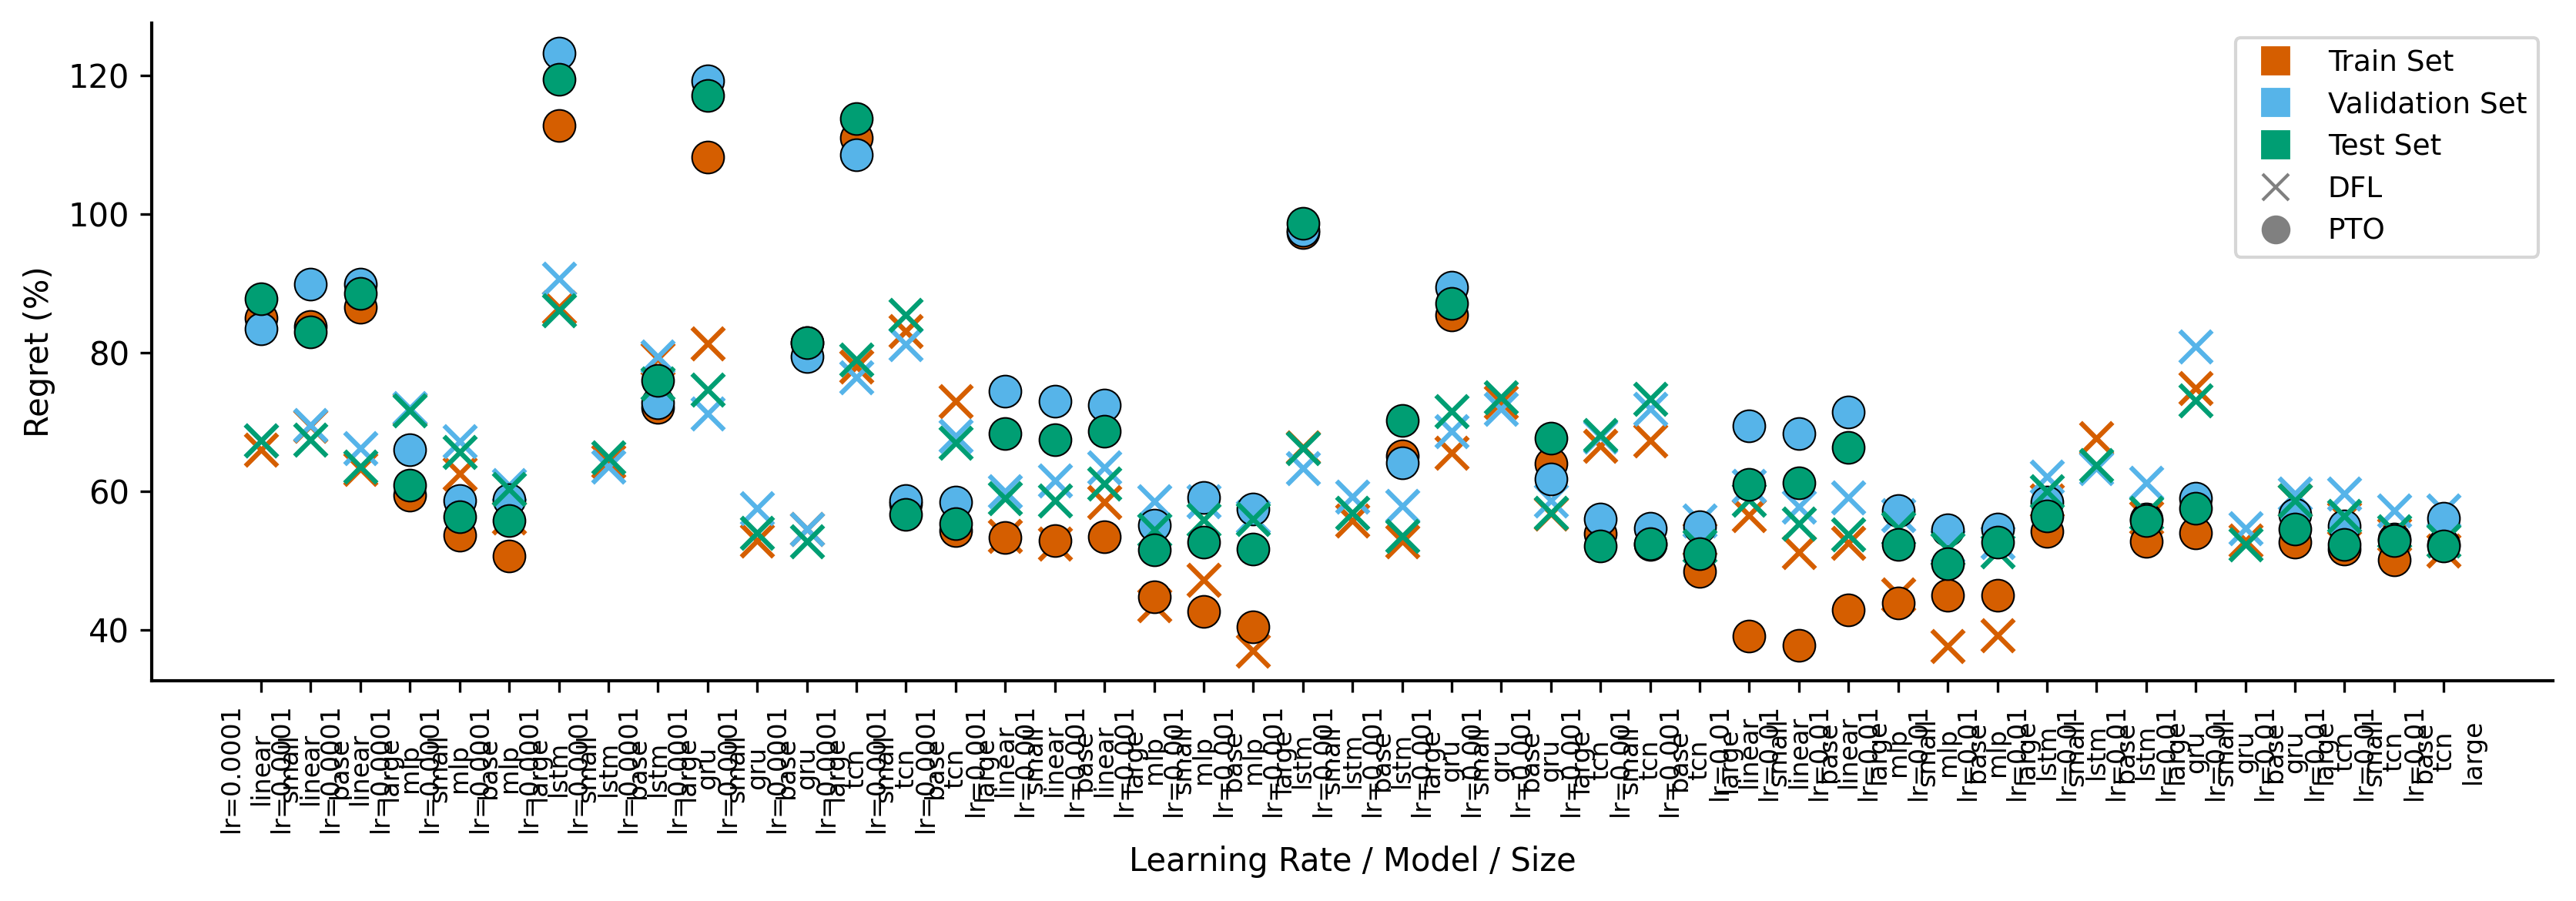

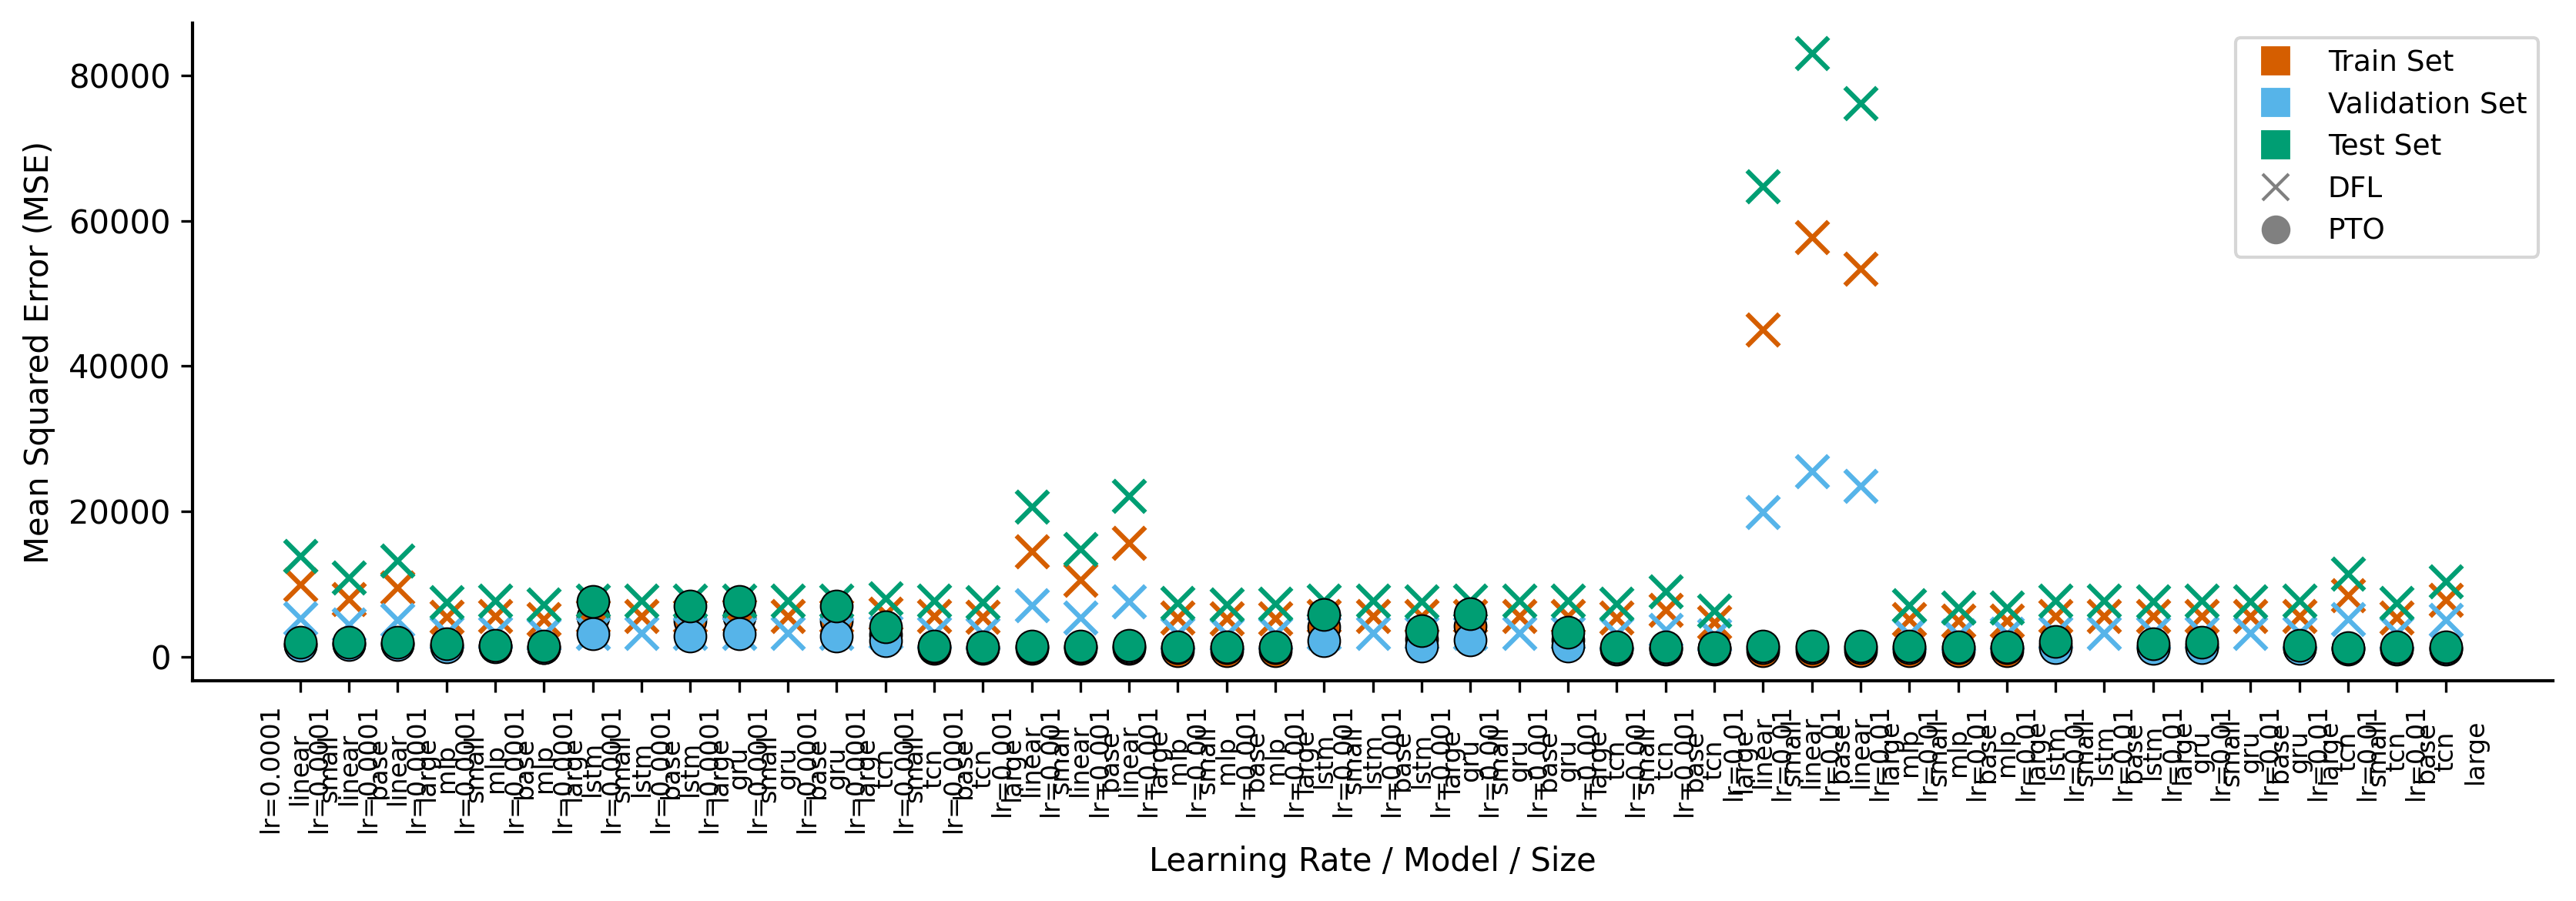

In [ ]:
# Create two plots against hierarchical x-axis: (lr, model family, size)
def parse_family_size(model_name):
    # model_name: e.g. 'mlp-small-decision' or 'gru-base'
    parts = model_name.split('-')
    family = parts[0] if len(parts) > 0 else ''
    size = parts[1] if len(parts) > 1 else ''
    return family, size

metrics['family'], metrics['size'] = zip(*metrics['model'].map(parse_family_size))

# Build hierarchical x labels
lr_values = sorted(metrics['learning_rate'].dropna().unique())
families = ['linear', 'mlp', 'lstm', 'gru', 'tcn']
sizes = ['small', 'base', 'large']

x_tuples = []
x_labels = []
for lr in lr_values:
    for family in families:
        for size in sizes:
            x_tuples.append( (lr, family, size) )
            x_labels.append(f"lr={lr}\n{family}\n{size}")

x_pos_map = {tup: i for i, tup in enumerate(x_tuples)}

# Add x position to metrics
metrics['x_pos'] = metrics.apply(lambda row: x_pos_map.get((row['learning_rate'], row['family'], row['size'])), axis=1)

dfl = metrics.loc[metrics['model'].str.contains('decision', na=False)].copy()
pto = metrics.loc[~metrics['model'].str.contains('decision', na=False)].copy()

# 1) Regret vs hierarchical x
plt.style.use('default')
fig, ax = plt.subplots(figsize=(max(7, len(x_labels)*0.25), 4), dpi=300)

for split, color in [('train', '#D55E00'), ('val', '#56B4E9'), ('test', '#009E73')]:
    if not dfl.empty:
        ax.scatter(
            dfl['x_pos'],
            dfl[split],
            color=color,
            marker='x',
            s=100,
            label=f'{split.capitalize()} (DFL)' if split=='train' else None
        )
    if not pto.empty:
        ax.scatter(
            pto['x_pos'],
            pto[split],
            color=color,
            marker='o',
            s=100,
            edgecolors='k',
            linewidth=0.5,
            label=f'{split.capitalize()} (PTO)' if split=='train' else None
        )

ax.set_xlabel('Learning Rate / Model / Size', fontsize=10)
ax.set_ylabel('Regret (%)', fontsize=10)
ax.set_xticks(range(len(x_labels)))
ax.set_xticklabels(x_labels, rotation=90, fontsize=8)

legend_elements = [
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='Train Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='Validation Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#009E73', markersize=10, label='Test Set'),
    Line2D([0], [0], color='gray', marker='x', linestyle='None', markersize=8, label='DFL'),
    Line2D([0], [0], color='gray', marker='o', linestyle='None', markersize=8, label='PTO')
]

ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(handles=legend_elements, loc='best', frameon=True, fontsize=9)

plt.tight_layout()
plt.savefig("plots/regret_vs_lrmodelsize_notsfm.pdf", format='pdf', bbox_inches='tight')
plt.show()

# 2) MSE vs hierarchical x
plt.style.use('default')
fig, ax = plt.subplots(figsize=(max(7, len(x_labels)*0.25), 4), dpi=300)

for split, color in [('train_mse', '#D55E00'), ('val_mse', '#56B4E9'), ('test_mse', '#009E73')]:
    if not dfl.empty:
        ax.scatter(
            dfl['x_pos'],
            dfl[split],
            color=color,
            marker='x',
            s=100,
            label=f'{split} (DFL)' if split=='train_mse' else None
        )
    if not pto.empty:
        ax.scatter(
            pto['x_pos'],
            pto[split],
            color=color,
            marker='o',
            s=100,
            edgecolors='k',
            linewidth=0.5,
            label=f'{split} (PTO)' if split=='train_mse' else None
        )

ax.set_xlabel('Learning Rate / Model / Size', fontsize=10)
ax.set_ylabel('Mean Squared Error (MSE)', fontsize=10)
ax.set_xticks(range(len(x_labels)))
ax.set_xticklabels(x_labels, rotation=90, fontsize=8)

legend_elements = [
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='Train Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='Validation Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#009E73', markersize=10, label='Test Set'),
    Line2D([0], [0], color='gray', marker='x', linestyle='None', markersize=8, label='DFL'),
    Line2D([0], [0], color='gray', marker='o', linestyle='None', markersize=8, label='PTO')
]

ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(handles=legend_elements, loc='best', frameon=True, fontsize=9)

plt.tight_layout()
plt.savefig("plots/mse_vs_lrmodelsize_notsfm.pdf", format='pdf', bbox_inches='tight')
plt.show()